# LSTM exploration

In [4]:
import pandas as pd
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import joblib
import numpy as np
from matplotlib.lines import Line2D
import matplotlib.transforms as transforms

sys.path.append('../')

from model_recurrent import Model

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-08 13:51:09,063	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-10-08 13:51:10,085	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [2]:
df = pd.read_csv("../full_data.csv")

# Global models

# Individual models

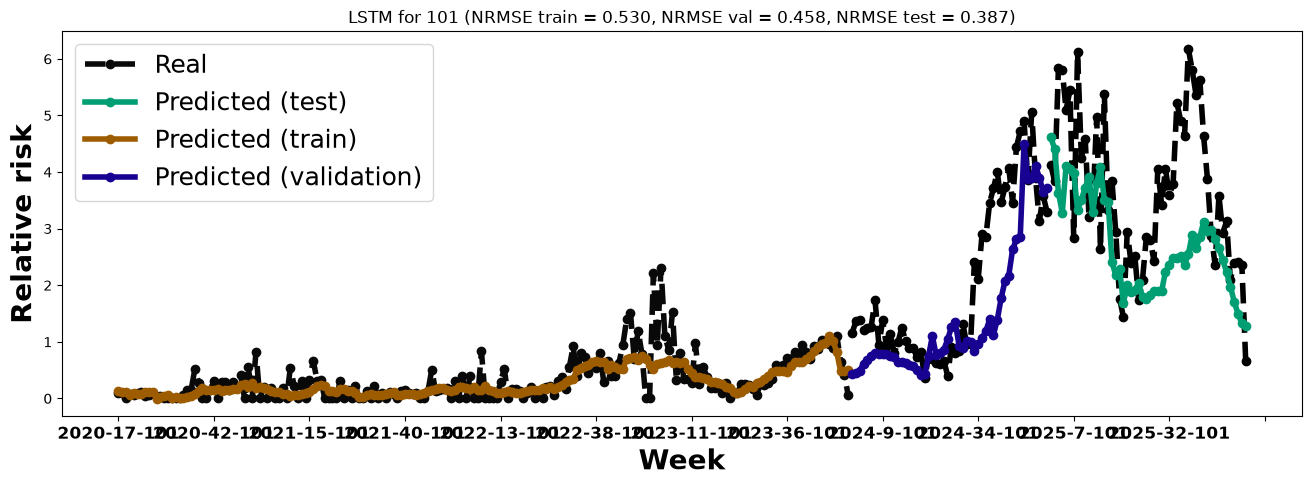

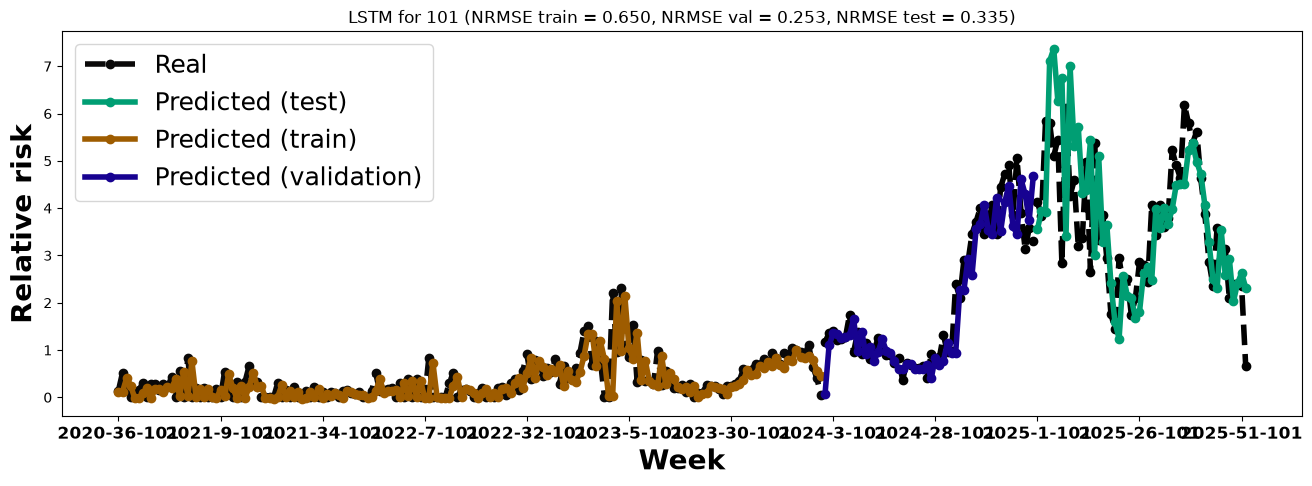

In [3]:
model0 = Model(df, "101")

model0.lstm_forecast_plot()
model0.lstm_forecast_plot(dif = True)

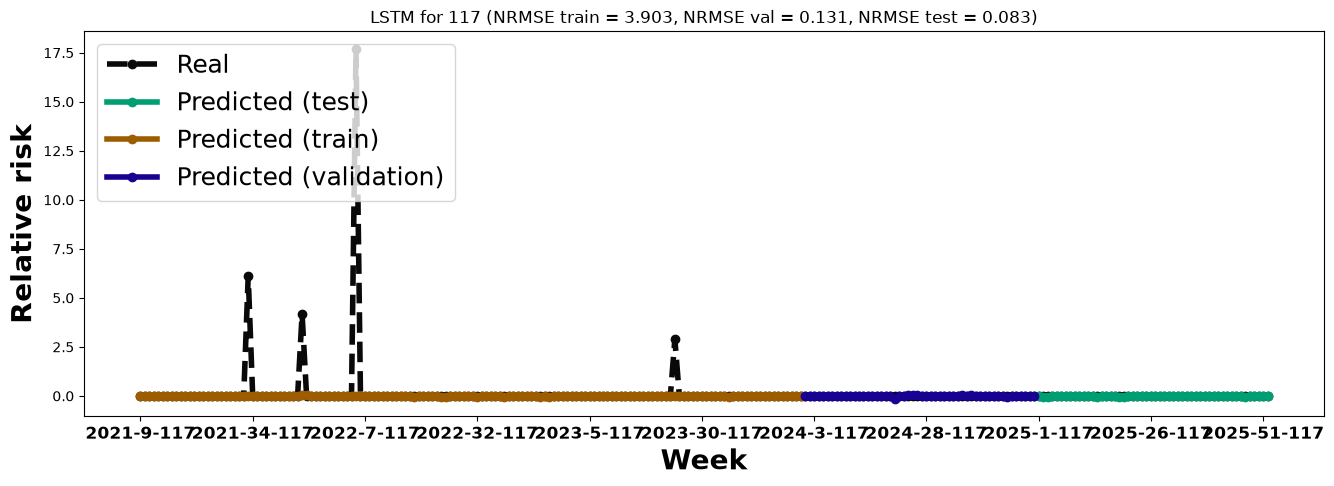

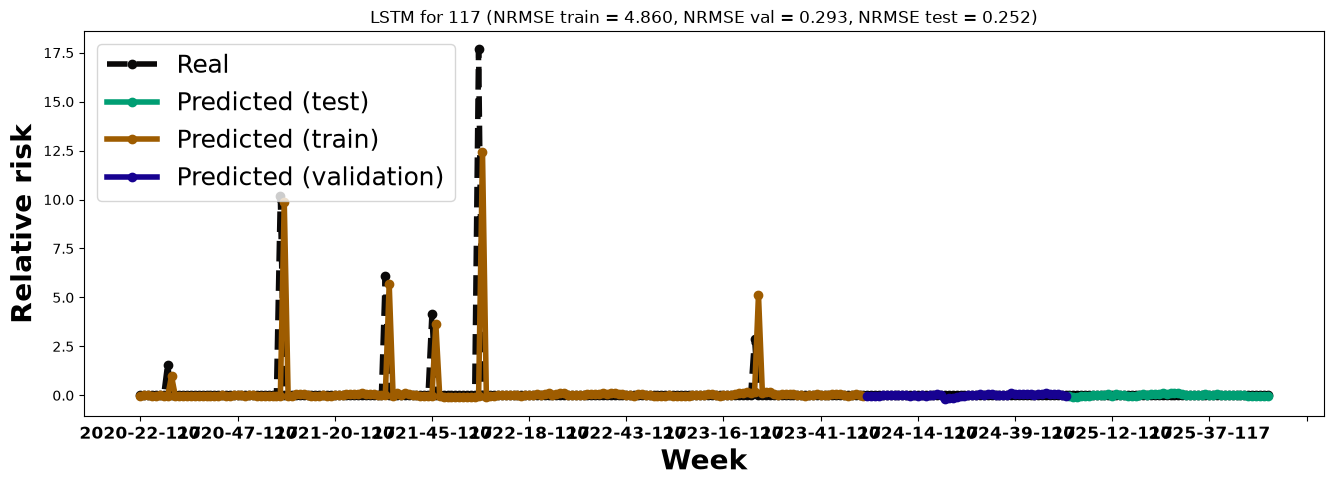

In [4]:
model0 = Model(df, "117")

model0.lstm_forecast_plot()
model0.lstm_forecast_plot(dif = True)

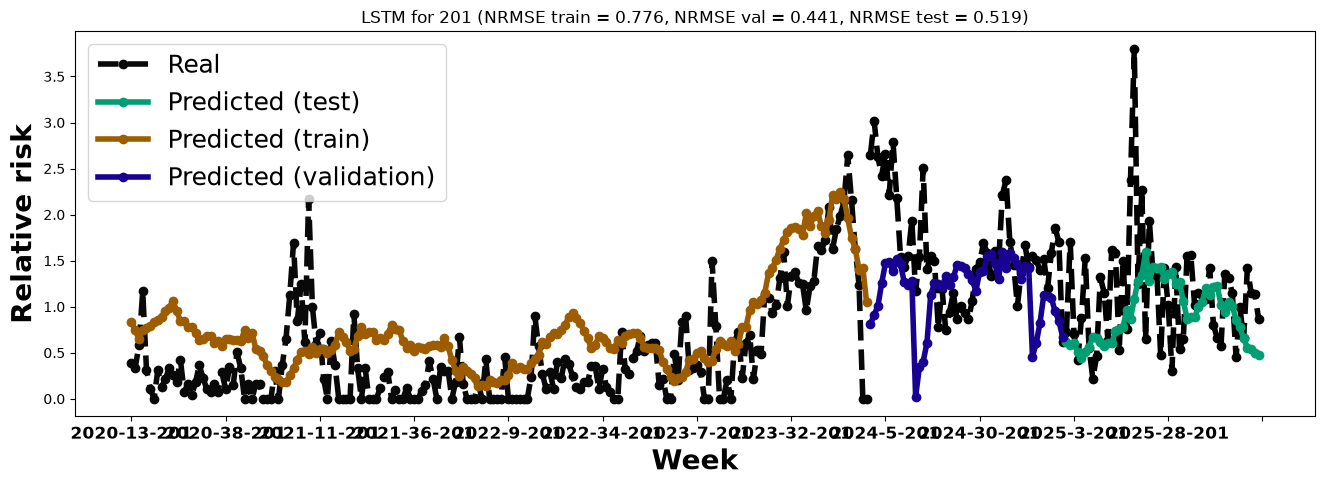

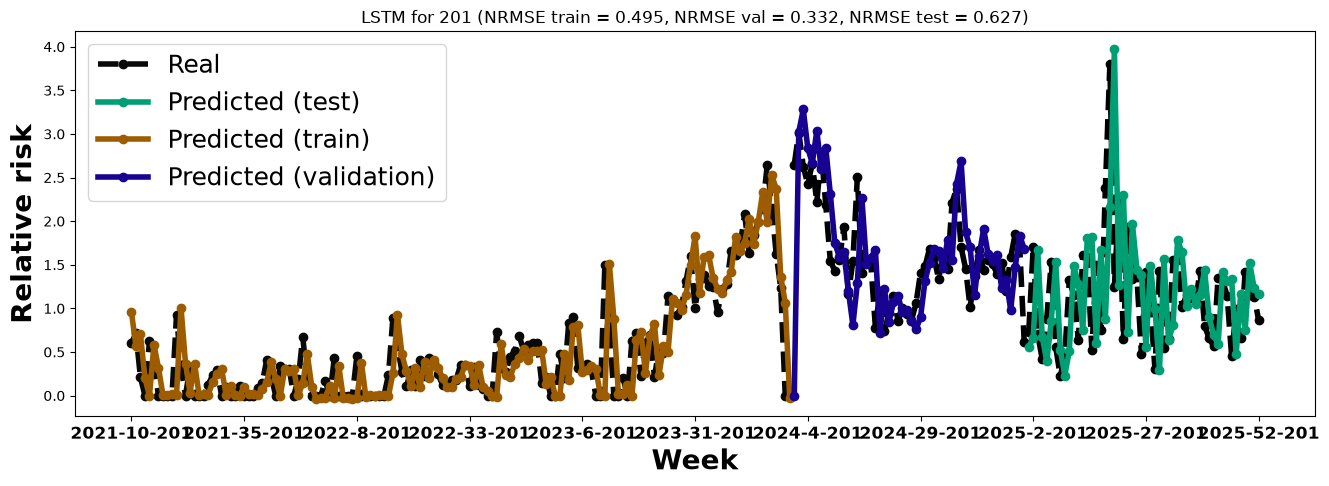

In [5]:
model0 = Model(df, "201")

model0.lstm_forecast_plot()
model0.lstm_forecast_plot(dif = True)

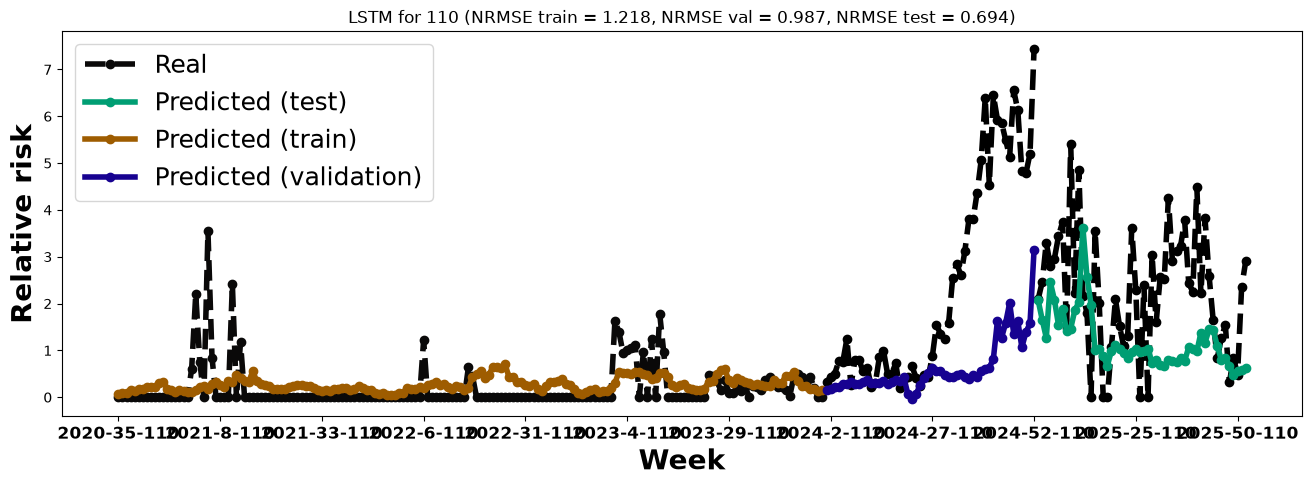

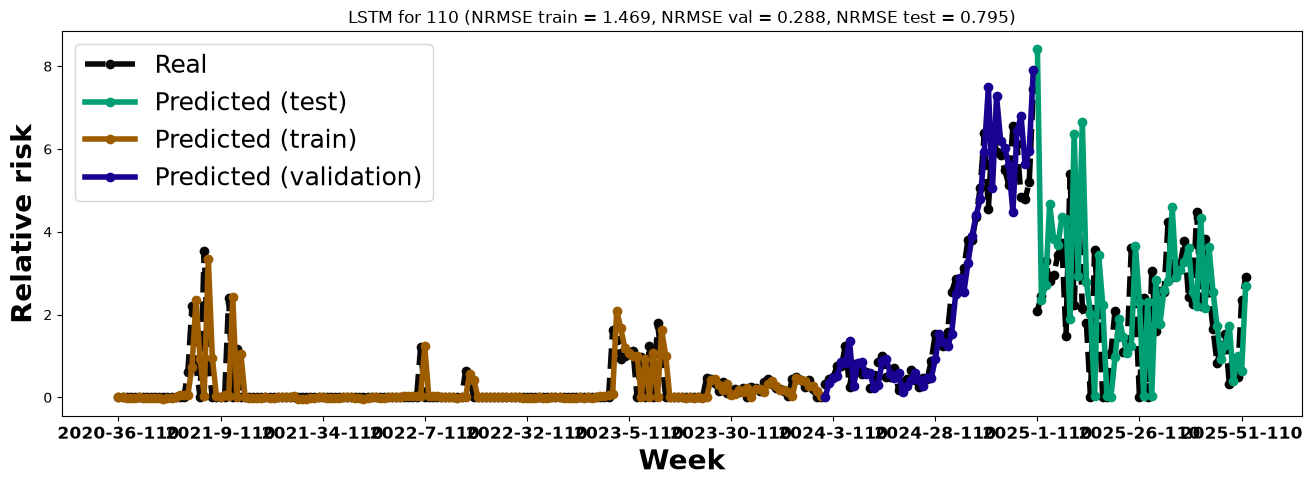

In [6]:
model0 = Model(df, "110")

model0.lstm_forecast_plot()
model0.lstm_forecast_plot(dif = True)

## Best non-recurrent models

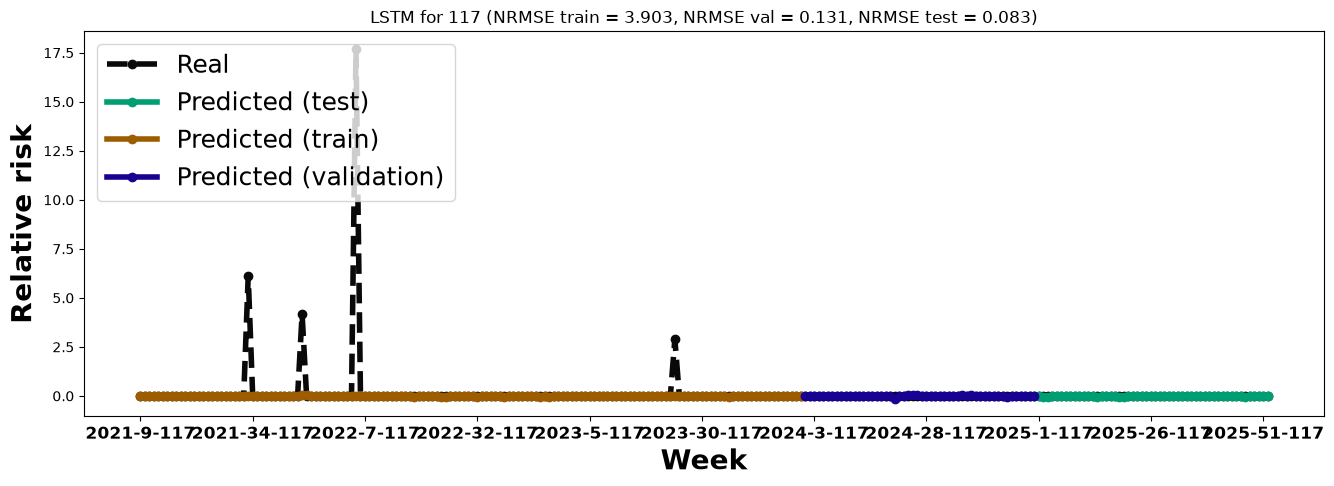

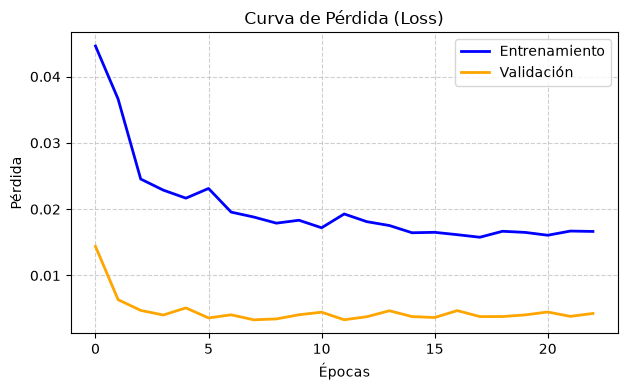

In [7]:
model0 = Model(df, "117")

model0.lstm_forecast_plot()
model0.lstm_eval_plots()

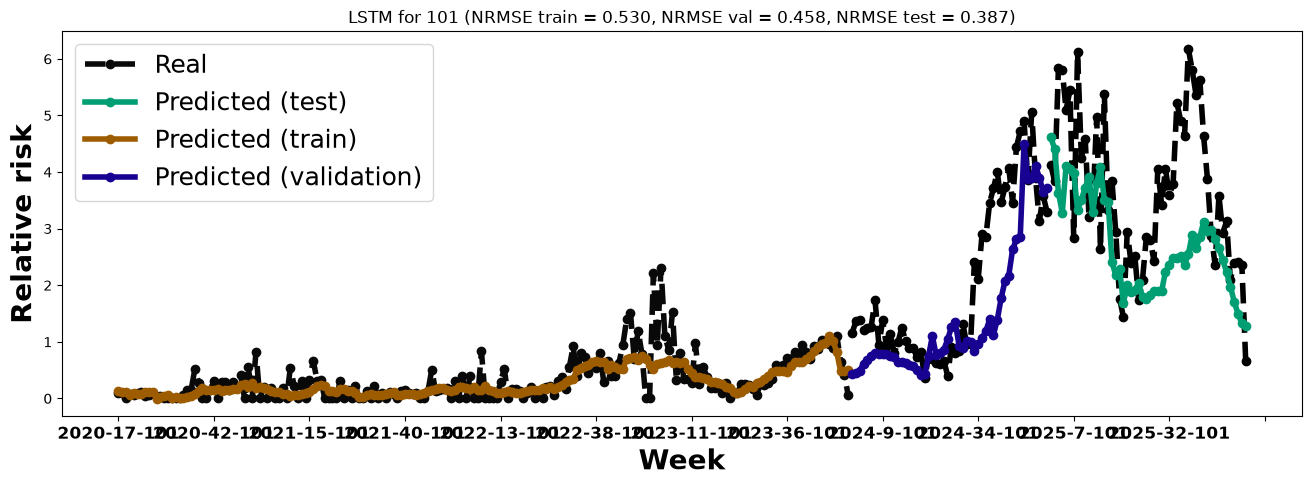

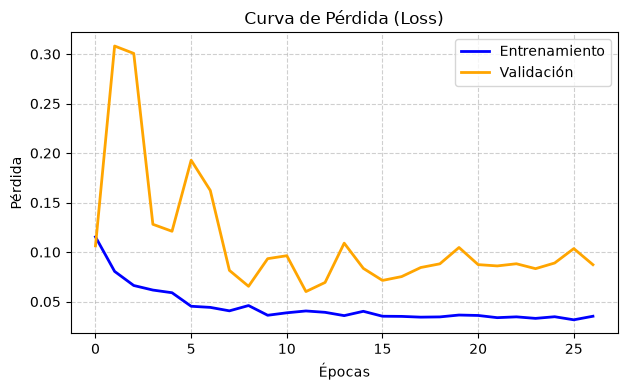

In [8]:
model0 = Model(df, "101")

model0.lstm_forecast_plot()
model0.lstm_eval_plots()

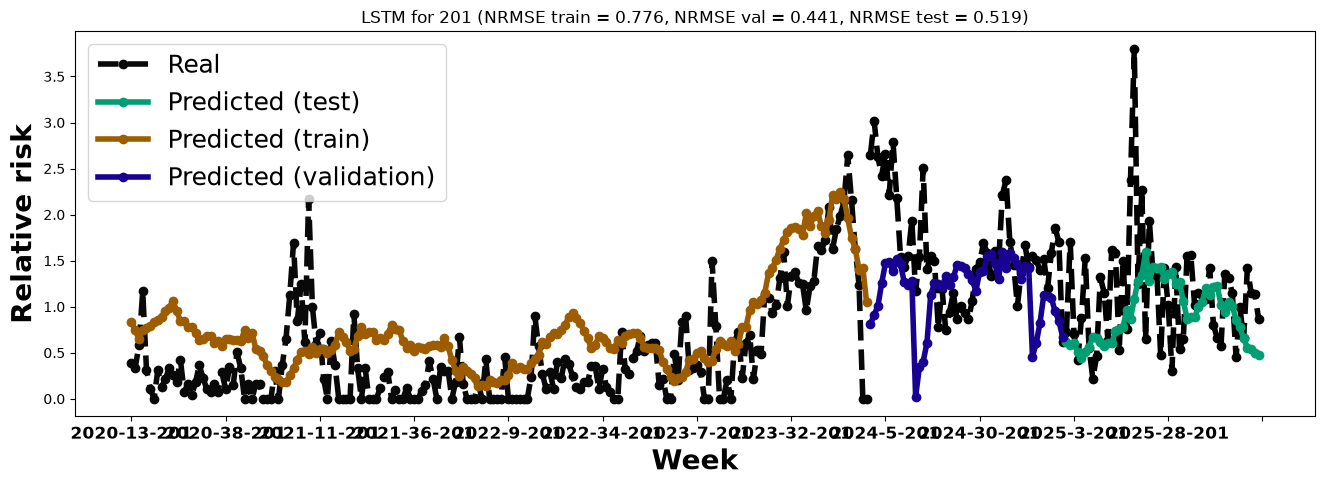

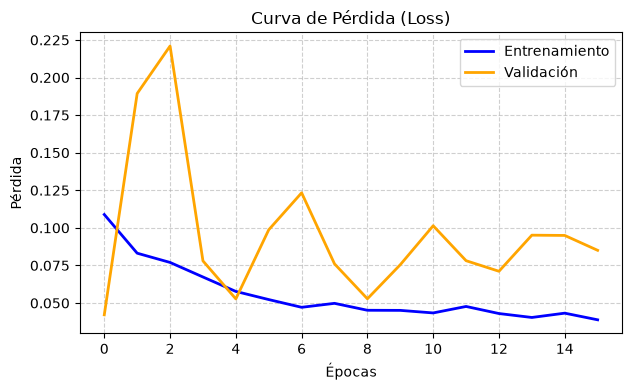

In [9]:
model0 = Model(df, "201")

model0.lstm_forecast_plot()
model0.lstm_eval_plots()

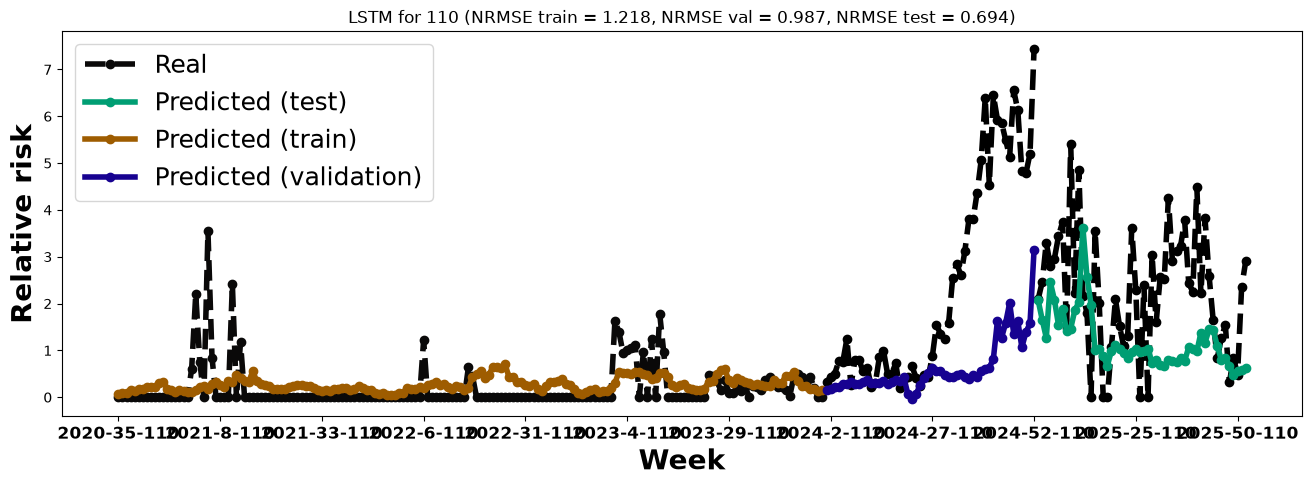

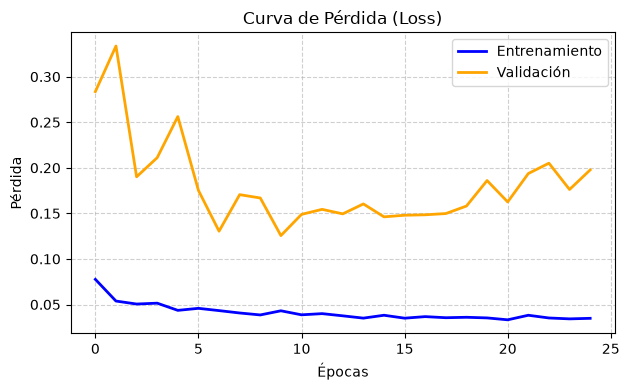

In [10]:
model0 = Model(df, "110")

model0.lstm_forecast_plot()
model0.lstm_eval_plots()

# NRMSE comparison for differencing and not differencing

C:\Windows\Temp\ipykernel_7956\2867331545.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 18, fontweight="bold")


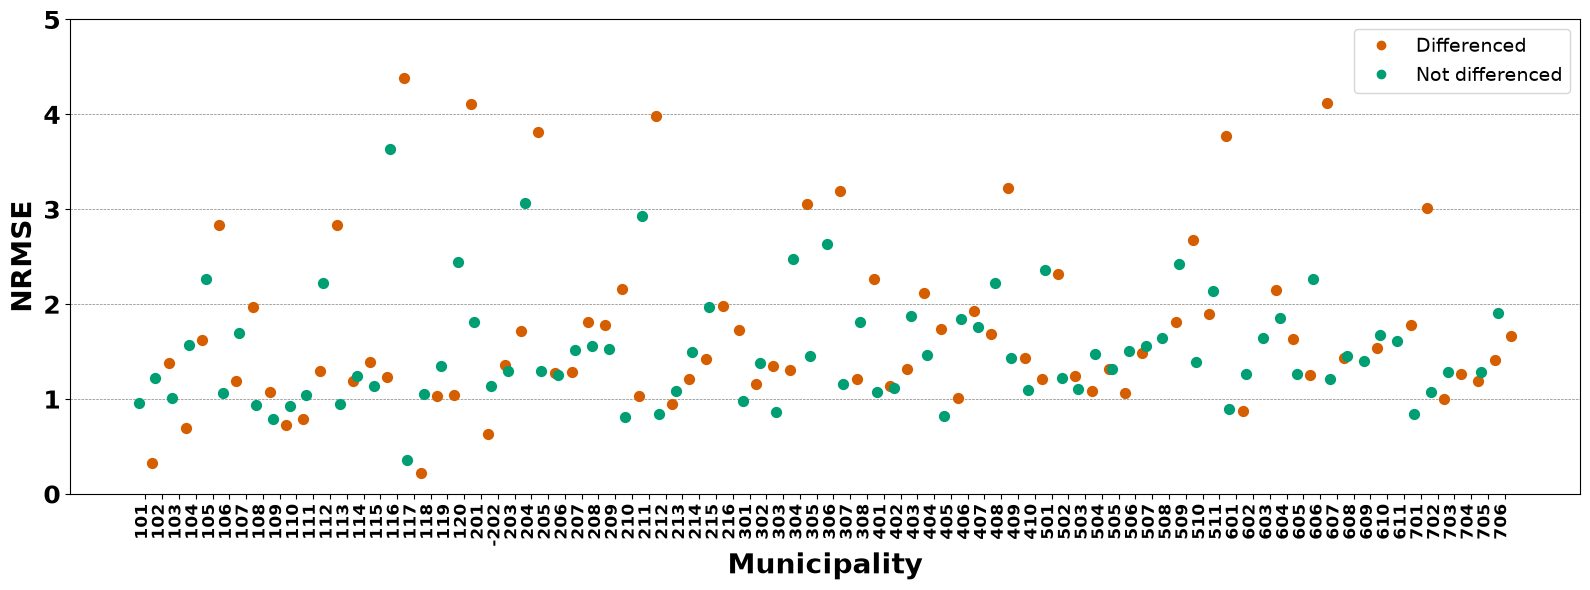

In [19]:
metrics = pd.read_csv(f"../data/metrics/nrmse_lstm_test.csv")

nodif_nrmse = metrics["nodif"]
dif_nrmse = metrics["dif"]

nodif_nrmse.head()
x = np.arange(len(metrics))

fig, ax = plt.subplots(figsize=(16, 6))

cap_width = 0.2

for i, row in metrics.iterrows():

    nodif_nrmse = metrics["nodif"]
    dif_nrmse = metrics["dif"]

    ax.scatter(
        # Plotting the mean as a point
        x[i],
        nodif_nrmse.iloc[i],
        color="#009E73",
        marker="o",
        s=50,
        zorder=4
    )

    x_full = x[i] + 0.8

    ax.scatter(
    # Plotting the individual model NRSME results
        x_full,
        dif_nrmse.iloc[i],
        color="#D55E00",
        s=50,
        zorder=3
    )

# Adding and transforming municipality labels in the x-axis so that visualization is more orderly and readable
ax.set_xticks(x + 0.4)
ax.set_xticklabels(metrics["canton"], rotation=90, ha="right", fontsize = 12, fontweight="bold")
dx = 4 / 72.0  
offset = transforms.ScaledTranslation(dx, 0, fig.dpi_scale_trans)
for label in ax.get_xticklabels():
    label.set_transform(label.get_transform() + offset)

style_handles = [
    # Adding the legend
    Line2D([0], [0], marker="o", color="#D55E00", linestyle="None", label="Differenced"),    
    Line2D([0], [0], marker = "o", linestyle="None", color="#009E73", label="Not differenced"),
]
    
ax.set_ylabel("NRMSE", fontsize = 20, fontweight="bold")
ax.set_xlabel("Municipality", fontsize = 20, fontweight="bold")
ax.set_ylim([0, 5])
ax.set_yticklabels(range(0, 6), fontsize = 18, fontweight="bold")
ax.legend(handles=style_handles, fontsize=14, loc="upper right")

plt.grid(axis='y', color = 'gray', linestyle = '--', linewidth = 0.5)
plt.tight_layout()
plt.show()